# BRCA ST patient D — pan-cancer Hist2Pheno

Andersson et al. *Nat Commun* 2021. HER2ST **D**: patient 10426, sections D1–D6, about 0.69 µm/px. No cell-type ground truth.
Predictions are the pan-cancer **cross-section** checkpoint `D_emph_L2_spatial_pancancer` (L1 / L12 / L2), spatial k=8.

JPEG 72 dpi is not used. µm/px is the 200 µm ST spot pitch. UNI rescales by `mpp/0.5` so the 16 px crop is **8 µm**.

One notebook per patient so the file does not store all 36 slides. Full-resolution PNGs stay in `data/ST/BRCA/pred_pancancer_section/figures/`.

```bash
SAMPLE=D bash code/External_val/BRCA_ST/demo.sh all
```


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
if not (REPO / "code").is_dir():
    REPO = Path("/nobackup2/users/lingyu/Python/Hist2Pheno")
sys.path.insert(0, str(REPO / "code" / "External_val" / "BRCA_ST"))

from brca_st_external import (  # noqa: E402
    PRED_ROOT,
    composition_table,
    discover_samples,
    geometry,
    sample_paths,
    ensure_l2_probs,
    plot_spatial,
)

PATIENT = "D"
group = discover_samples(PATIENT)
fig_dir = PRED_ROOT / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)
# Re-run the plot cell after changing these. Files are written only when SAVE_FIGURES is True.
SAVE_FIGURES = False
FIGSIZE = (17.2, 6.6)
DPI = 160
HE_MAX_SIDE = 1400
MARKER_PX = 2.2
print(f"{PATIENT}  n={len(group)}")
for sample in group:
    g = geometry(sample)
    print(
        f"{sample}  mpp={g['mpp_um']:.4f} µm/px  "
        f"native16={g['patch_um_if_native_16px']:.2f} µm  "
        f"after rescale={g['patch_um_after_rescale']:.1f} µm  "
        f"scale={g['scale']:.4f}  ({g['mpp_source']})"
    )
    print(f"  pred exists: {sample_paths(sample)['pred'].is_file()}")


D  n=6
10426_HE_BT_C1  mpp=0.6863 µm/px  native16=10.98 µm  after rescale=8.0 µm  scale=1.3726  (ST 200 µm spot pitch (D1))
  pred exists: True
10426_HE_BT_C2  mpp=0.6867 µm/px  native16=10.99 µm  after rescale=8.0 µm  scale=1.3734  (ST 200 µm spot pitch (D2))
  pred exists: True
10426_HE_BT_D1  mpp=0.6883 µm/px  native16=11.01 µm  after rescale=8.0 µm  scale=1.3767  (ST 200 µm spot pitch (D3))
  pred exists: True
10426_HE_BT_D2  mpp=0.6860 µm/px  native16=10.98 µm  after rescale=8.0 µm  scale=1.3720  (ST 200 µm spot pitch (D4))
  pred exists: True
10426_HE_BT_E1  mpp=0.6876 µm/px  native16=11.00 µm  after rescale=8.0 µm  scale=1.3752  (ST 200 µm spot pitch (D5))
  pred exists: True
10426_HE_BT_E2  mpp=0.6879 µm/px  native16=11.01 µm  after rescale=8.0 µm  scale=1.3758  (ST 200 µm spot pitch (D6))
  pred exists: True


## D — composition and spatial labels


===== D L1 =====


fraction                                               \
sample      10426_HE_BT_C1 10426_HE_BT_C2 10426_HE_BT_D1 10426_HE_BT_D2   
class                                                                     
Immune               0.533          0.655          0.451          0.554   
Stromal              0.301          0.207          0.283          0.273   
Endothelial          0.163          0.134          0.252          0.169   
Epithelial           0.004          0.005          0.015          0.004   
Neural                 NaN            NaN          0.000            NaN   

                                               mean_conf                 \
sample      10426_HE_BT_E1 10426_HE_BT_E2 10426_HE_BT_C1 10426_HE_BT_C2   
class                                                                     
Immune               0.541          0.542          0.566          0.620   
Stromal              0.225          0.231          0.465          0.474   
Endothelial          0.226          0.219          0.449          0.450   
Epithelial           0.007          0.008          0.416          0.475   
Neural                 NaN            NaN            NaN            NaN   

                                                                         \
sample      10426_HE_BT_D1 10426_HE_BT_D2 10426_HE_BT_E1 10426_HE_BT_E2   
class                                                                     
Immune               0.565          0.586          0.588          0.603   
Stromal              0.477          0.476          0.466          0.479   
Endothelial          0.466          0.474          0.477          0.480   
Epithelial           0.456          0.448          0.478          0.486   
Neural               0.292            NaN            NaN            NaN   

                         n                                               \
sample      10426_HE_BT_C1 10426_HE_BT_C2 10426_HE_BT_D1 10426_HE_BT_D2   
class                                                                     
Immune             30596.0        40506.0        27065.0        32882.0   
Stromal            17275.0        12810.0        16988.0        16160.0   
Endothelial         9351.0         8268.0        15137.0        10041.0   
Epithelial           219.0          285.0          878.0          218.0   
Neural                 NaN            NaN            1.0            NaN   

                                           
sample      10426_HE_BT_E1 10426_HE_BT_E2  
class                                      
Immune             33925.0        34355.0  
Stromal            14124.0        14659.0  
Endothelial        14140.0        13874.0  
Epithelial           463.0          489.0  
Neural                 NaN            NaN

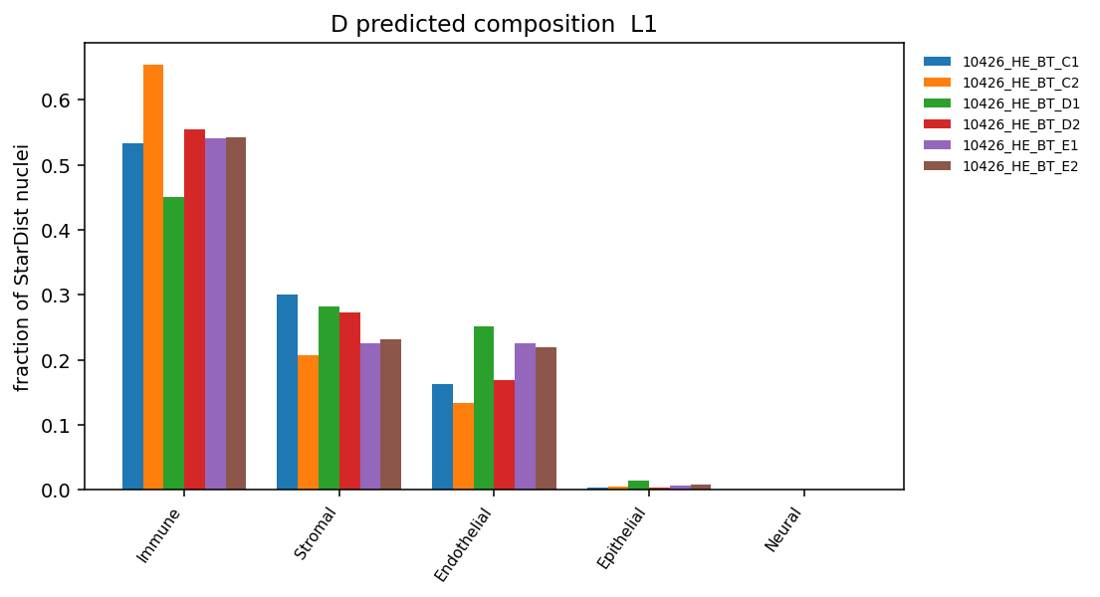

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/D_composition_L1.png

===== D L12 =====


fraction                                               \
sample      10426_HE_BT_C1 10426_HE_BT_C2 10426_HE_BT_D1 10426_HE_BT_D2   
class                                                                     
T_cell               0.655          0.748          0.543          0.701   
Stromal              0.294          0.194          0.359          0.255   
B_Plasma             0.016          0.027          0.041          0.013   
Endothelial          0.014          0.011          0.028          0.020   
Myeloid              0.018          0.016          0.014          0.007   
Epithelial           0.003          0.004          0.015          0.004   
Tumor                0.000          0.000          0.000          0.000   

                                               mean_conf                 \
sample      10426_HE_BT_E1 10426_HE_BT_E2 10426_HE_BT_C1 10426_HE_BT_C2   
class                                                                     
T_cell               0.656          0.654          0.465          0.507   
Stromal              0.264          0.270          0.391          0.389   
B_Plasma             0.032          0.027          0.379          0.417   
Endothelial          0.029          0.028          0.323          0.312   
Myeloid              0.010          0.010          0.303          0.316   
Epithelial           0.009          0.010          0.348          0.385   
Tumor                0.000          0.000          0.361          0.403   

                                                                         \
sample      10426_HE_BT_D1 10426_HE_BT_D2 10426_HE_BT_E1 10426_HE_BT_E2   
class                                                                     
T_cell               0.447          0.493          0.480          0.498   
Stromal              0.410          0.407          0.394          0.405   
B_Plasma             0.389          0.389          0.403          0.398   
Endothelial          0.333          0.337          0.336          0.338   
Myeloid              0.285          0.286          0.287          0.284   
Epithelial           0.400          0.396          0.404          0.417   
Tumor                0.291          0.410          0.401          0.321   

                         n                                               \
sample      10426_HE_BT_C1 10426_HE_BT_C2 10426_HE_BT_D1 10426_HE_BT_D2   
class                                                                     
T_cell             37626.0        46296.0        32611.0        41569.0   
Stromal            16907.0        11987.0        21549.0        15127.0   
B_Plasma             911.0         1641.0         2471.0          756.0   
Endothelial          779.0          696.0         1657.0         1168.0   
Myeloid             1008.0          973.0          842.0          413.0   
Epithelial           188.0          263.0          930.0          255.0   
Tumor                 22.0           13.0            9.0           13.0   

                                           
sample      10426_HE_BT_E1 10426_HE_BT_E2  
class                                      
T_cell             41102.0        41459.0  
Stromal            16526.0        17127.0  
B_Plasma            1992.0         1726.0  
Endothelial         1829.0         1781.0  
Myeloid              633.0          627.0  
Epithelial           564.0          652.0  
Tumor                  6.0            5.0

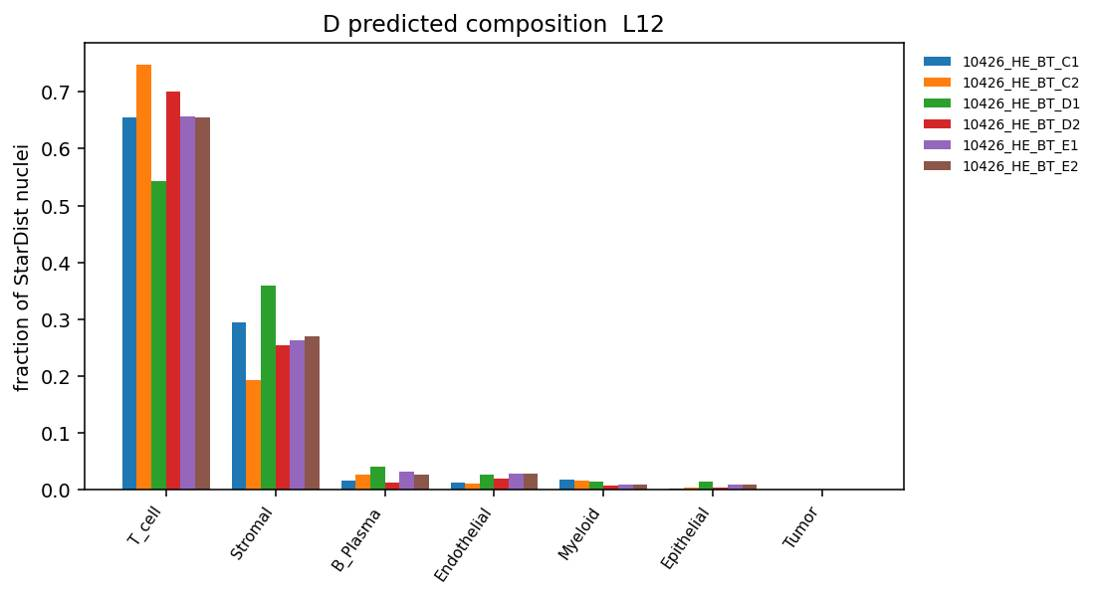

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/D_composition_L12.png

===== D L2 =====


fraction                                               \
sample            10426_HE_BT_C1 10426_HE_BT_C2 10426_HE_BT_D1 10426_HE_BT_D2   
class                                                                           
B_cell                     0.433          0.499          0.430          0.452   
Fibroblast                 0.289          0.210          0.170          0.198   
CD4_T                      0.149          0.186          0.097          0.173   
Endothelial                0.067          0.054          0.152          0.093   
Stromal                    0.022          0.015          0.081          0.047   
Plasma                     0.007          0.008          0.031          0.012   
CD8_T                      0.015          0.009          0.016          0.007   
Neutrophil                 0.014          0.010          0.009          0.010   
Epithelial                 0.002          0.002          0.008          0.003   
Tregs                      0.001          0.004          0.000          0.003   
Injury_epithelial          0.002          0.001          0.007          0.001   
DC                         0.000          0.002          0.001          0.000   
Tumor                      0.001          0.000          0.000          0.000   
Myoepithelial                NaN          0.000          0.000            NaN   
Myofibroblast              0.000          0.000          0.000          0.000   
DCIS                       0.000          0.000            NaN          0.000   
Alveolar                   0.000            NaN          0.000          0.000   
Macrophage                 0.000          0.000          0.000            NaN   
NK                           NaN            NaN          0.000            NaN   

                                                     mean_conf                 \
sample            10426_HE_BT_E1 10426_HE_BT_E2 10426_HE_BT_C1 10426_HE_BT_C2   
class                                                                           
B_cell                     0.477          0.423          0.347          0.398   
Fibroblast                 0.147          0.164          0.276          0.294   
CD4_T                      0.134          0.173          0.289          0.332   
Endothelial                0.135          0.127          0.256          0.249   
Stromal                    0.052          0.051          0.299          0.302   
Plasma                     0.024          0.028          0.237          0.263   
CD8_T                      0.005          0.006          0.232          0.240   
Neutrophil                 0.012          0.013          0.229          0.239   
Epithelial                 0.004          0.004          0.245          0.256   
Tregs                      0.006          0.007          0.224          0.265   
Injury_epithelial          0.004          0.004          0.234          0.272   
DC                         0.001          0.000          0.245          0.272   
Tumor                      0.000          0.000          0.296          0.219   
Myoepithelial              0.000          0.000            NaN          0.185   
Myofibroblast              0.000          0.000          0.206          0.234   
DCIS                       0.000          0.000          0.181          0.358   
Alveolar                   0.000          0.000          0.175            NaN   
Macrophage                   NaN          0.000          0.192          0.171   
NK                         0.000            NaN            NaN            NaN   

                                                                               \
sample            10426_HE_BT_D1 10426_HE_BT_D2 10426_HE_BT_E1 10426_HE_BT_E2   
class                                                                           
B_cell                     0.364          0.352          0.374          0.371   
Fibroblast                 0.250          0.274          0.256          0.265   
CD4_T                      0.276          0.311      

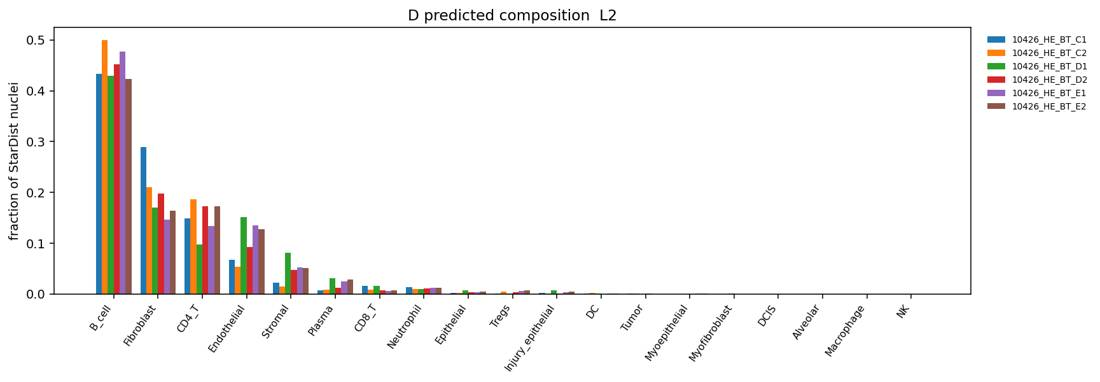

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/D_composition_L2.png
10426_HE_BT_C1


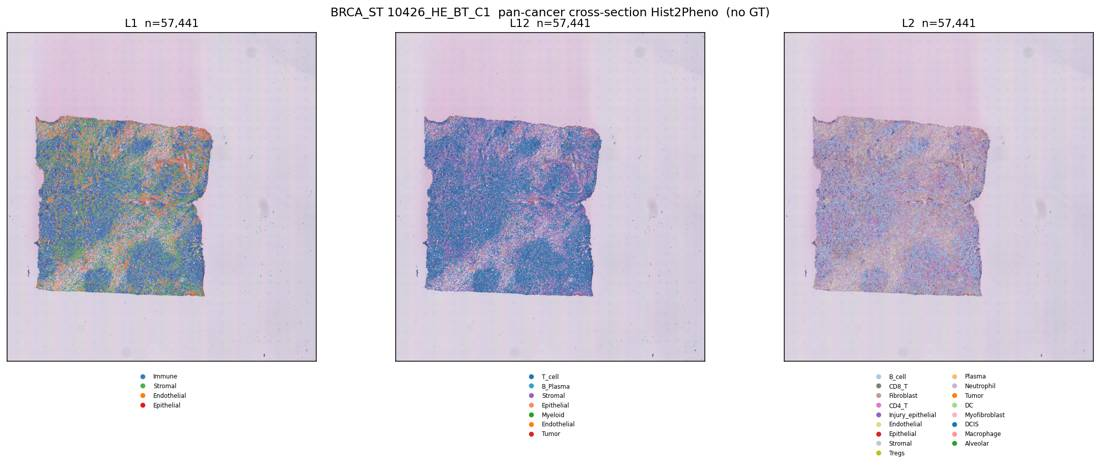

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/10426_HE_BT_C1_spatial_L1_L12_L2.png
10426_HE_BT_C2


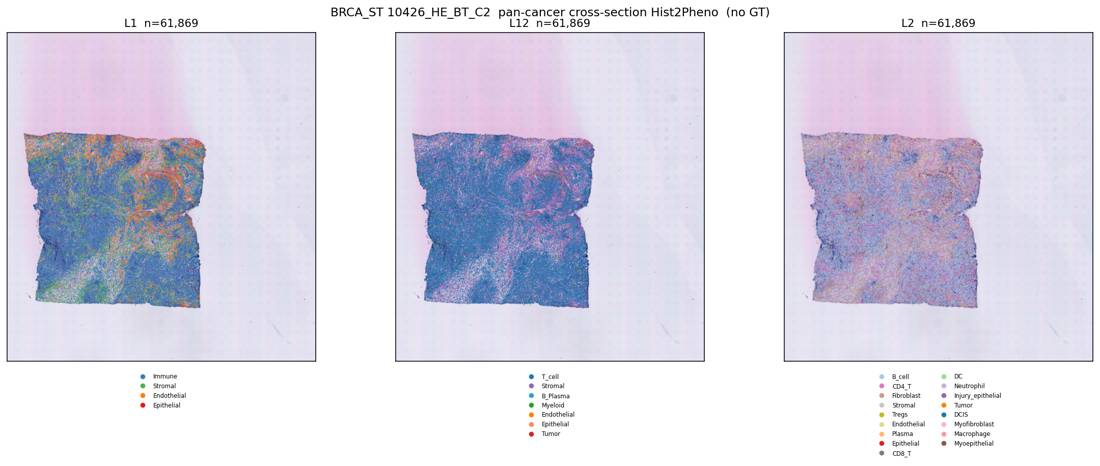

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/10426_HE_BT_C2_spatial_L1_L12_L2.png
10426_HE_BT_D1


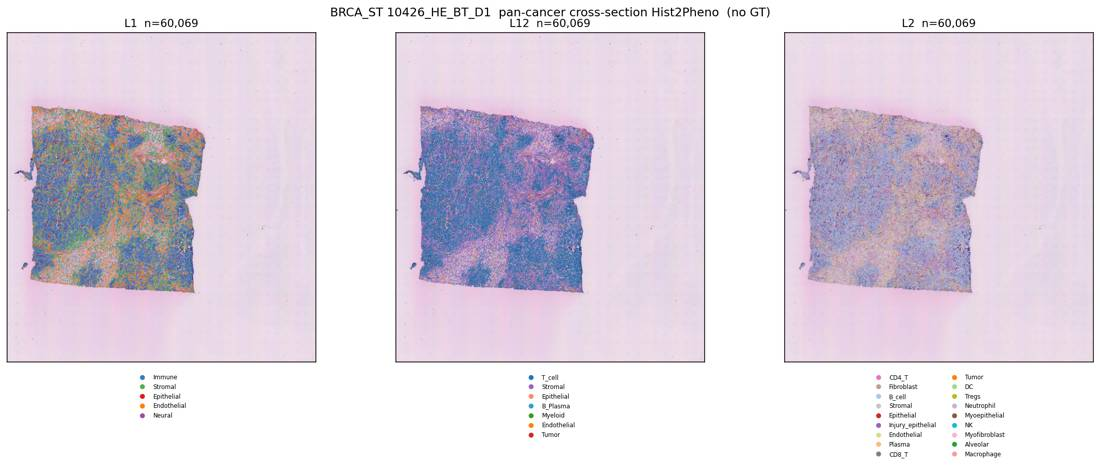

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/10426_HE_BT_D1_spatial_L1_L12_L2.png
10426_HE_BT_D2


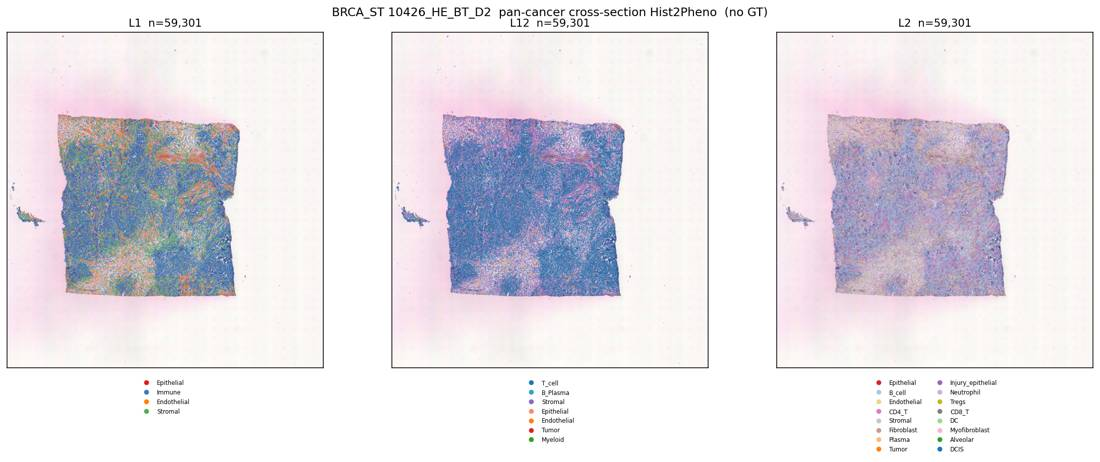

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/10426_HE_BT_D2_spatial_L1_L12_L2.png
10426_HE_BT_E1


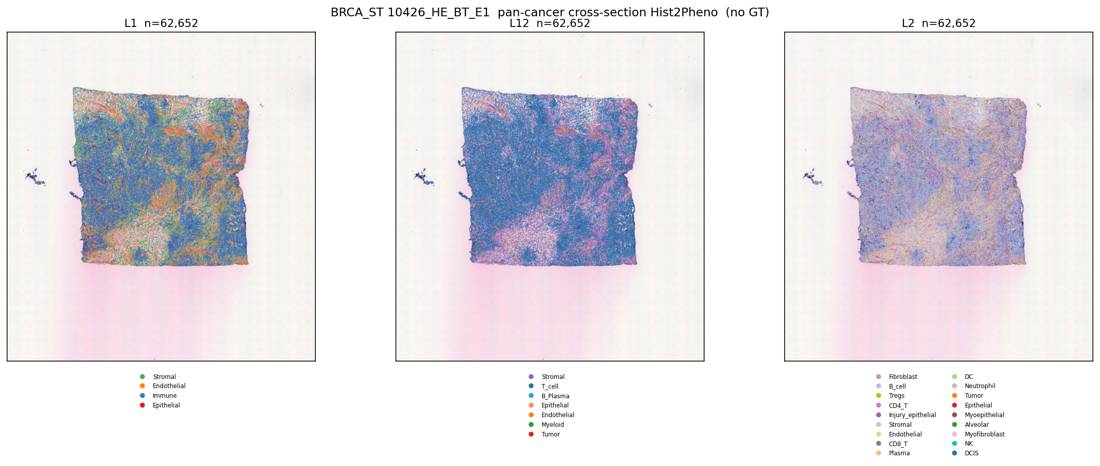

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/10426_HE_BT_E1_spatial_L1_L12_L2.png
10426_HE_BT_E2


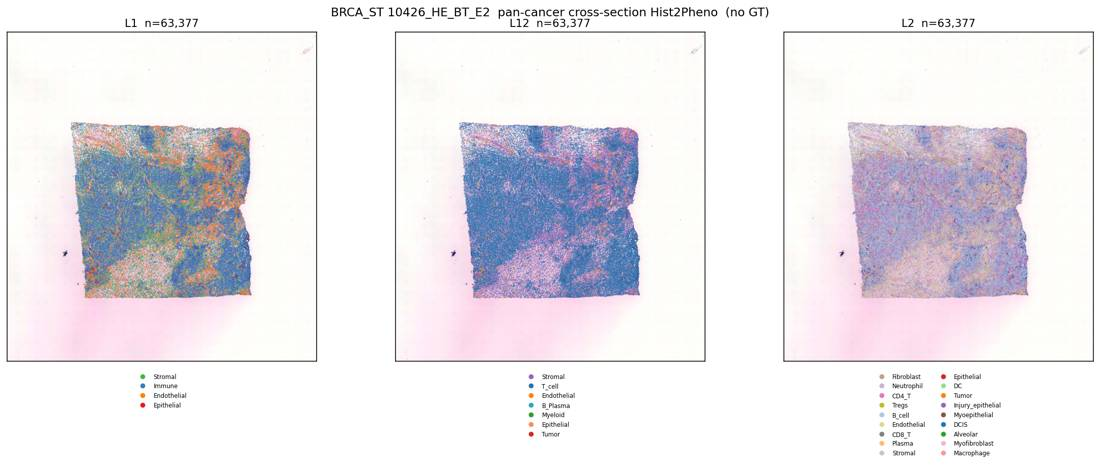

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/10426_HE_BT_E2_spatial_L1_L12_L2.png


In [2]:
missing = [s for s in group if not sample_paths(s)["pred"].is_file()]
if missing:
    raise FileNotFoundError(
        f"No predictions yet for {PATIENT}: "
        + ", ".join(missing)
        + f". Run: SAMPLE={PATIENT} bash code/External_val/BRCA_ST/demo.sh all"
    )

display(Markdown(f"## {PATIENT} — composition and spatial labels"))
comp = composition_table(group)
for head in ("L1", "L12", "L2"):
    sub = comp.loc[comp["head"] == head].copy()
    order = sub.groupby("class")["fraction"].max().sort_values(ascending=False).index
    wide = (
        sub.pivot_table(index="class", columns="sample", values=["fraction", "n", "mean_conf"])
        .reindex(order)
    )
    print(f"\n===== {PATIENT} {head} =====")
    display(wide.round(3))

    classes = list(order)
    sections = list(dict.fromkeys(sub["sample"]))
    fig, ax = plt.subplots(figsize=(max(8, 0.55 * len(classes) + 2), 4.4))
    x = range(len(classes))
    width = 0.8 / max(len(sections), 1)
    for i, section in enumerate(sections):
        ss = sub.loc[sub["sample"] == section].set_index("class")
        vals = [float(ss.loc[c, "fraction"]) if c in ss.index else 0.0 for c in classes]
        ax.bar([xi + i * width for xi in x], vals, width=width, label=section)
    ax.set_xticks([xi + width * (len(sections) - 1) / 2 for xi in x])
    ax.set_xticklabels(classes, rotation=55, ha="right", fontsize=8)
    ax.set_ylabel("fraction of StarDist nuclei")
    ax.set_title(f"{PATIENT} predicted composition  {head}")
    ax.legend(frameon=False, fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.tight_layout()
    if SAVE_FIGURES:
        out = fig_dir / f"{PATIENT}_composition_{head}.png"
        fig.savefig(out, dpi=DPI, bbox_inches="tight")
        print(out)
    display(fig)
    plt.close(fig)

for fig in plot_spatial(
    group,
    figsize=FIGSIZE,
    dpi=DPI,
    he_max_side=HE_MAX_SIDE,
    marker_px=MARKER_PX,
    save=SAVE_FIGURES,
):
    display(fig)
    plt.close(fig)


## Histology-derived niche indices (TLS / SRI / TNI)

Same implementation as `code/Xenium_lung/histology_derived_niche_index.ipynb` §3, via `Hist2Pheno_pkg/histology_niche_index.py`. Lung ARI / FRI are not used.

Scores use **L2 softmax**, not the argmax label. `ensure_l2_probs` caches `{sample}_l2_probs.npz`.

| Index | Abundance | Spatial (radius R) |
|--|--|--|
| **TLS** | sum(B_cell + Plasma + CD4_T + CD8_T + Tregs + DC) | `(B_local × T_local × DC_local)^(1/3)` |
| **SRI** | (Fibroblast + Myofibroblast + Stromal) / epithelium | Fib_local / Epi_local |
| **TNI** | (fibroblast + Macrophage + Endothelial) / epithelium | `(Fib × Mac × Endo)^(1/3) / Epi_local` |

Epithelium = Epithelial, Tumor, Alveolar, Injury_epithelial, DCIS, Myoepithelial. NK is left out of TLS. `spatial_HE` is native JPEG pixels, so R = **55 µm** uses this slide's own µm/px. TLS, SRI, and TNI are each a 1×3 row. This notebook embeds a resized preview; the saved PNG is full resolution.


In [3]:
import importlib

for _p in (REPO / "code" / "Hist2Pheno_pkg", REPO / "code" / "Xenium_lung"):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import histology_niche_index as hni
importlib.reload(hni)
import histology_derived_niche_index as hdni
importlib.reload(hdni)
from histology_niche_index import OrganNicheConfig

import anndata as ad

TLS_RADIUS_UM = 55.0
RECOMPUTE_NICHE = False

BRCA_ST_NICHE = OrganNicheConfig(
    pan_organ="pancancer_brca_st",
    tls_b=("B_cell", "Plasma"),
    tls_t=("CD4_T", "CD8_T", "Tregs"),
    tls_dc=("DC",),
    epithelium=(
        "Epithelial", "Tumor", "Alveolar",
        "Injury_epithelial", "DCIS", "Myoepithelial",
    ),
    fibroblast=("Fibroblast", "Myofibroblast", "Stromal"),
    endothelial=("Endothelial",),
    macrophage=("Macrophage",),
    um_per_he_pixel=float(geometry(group[0])["mpp_um"]),
    spatial_radius_um=TLS_RADIUS_UM,
    cohort="BRCA_ST",
)
display(hni.index_formula_table(BRCA_ST_NICHE))


,index,formula
0,TLS,sum(B_cell+ Plasma+ CD4_T+ CD8_T+ Tregs+ DC)
1,TLS_spatial,(B_local × T_local × DC_local)^(1/3) within ra...
2,SRI_ratio,Fibroblast+Myofibroblast+Stromal / Epithelial+...
3,SRI_spatial,Fib_local / Epi_local within radius R μm
4,TNI_ratio,(Fibroblast+Myofibroblast+Stromal + Macrophage...
5,TNI_spatial,(Fib_local × myeloid_local × Endo_local)^(1/3)...


## D — TLS / SRI / TNI

[probs] cache /nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/10426_HE_BT_C1/10426_HE_BT_C1_l2_probs.npz  (57441, 20)
[niche] wrote /nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/10426_HE_BT_C1/10426_HE_BT_C1_niche_indices.h5ad  n=57,441
  TLS hotspot: {'n_cells_total': 57441, 'n_candidate_cells': 2873, 'fraction_candidate': 0.05001653870928431, 'max_tls_spatial': 0.2336206885780907, 'mean_tls_spatial_candidate': 0.19061024504327168, 'centroid_x': 2930.499313007279, 'centroid_y': 5755.04769959468}
  mean TLS=0.571  TLS_spatial=0.143  SRI=18.349  TNI=28.378
[probs] cache /nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/10426_HE_BT_C2/10426_HE_BT_C2_l2_probs.npz  (61869, 20)
[niche] wrote /nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/10426_HE_BT_C2/10426_HE_BT_C2_niche_indices.h5ad  n=61,869
  TLS hotspot: {'n_cells_total': 61869, 'n_candidate_cells': 3094, 'fraction_

,sample,n,TLS_mean,TLS_median,TLS_p95,TLS_max,TLS_spatial_mean,TLS_spatial_median,TLS_spatial_p95,TLS_spatial_max,pearson,spearman,top5_jaccard,abundance_top5_also_spatial_top5,TLS_spatial_mean_in_abundance_top5,TLS_mean_in_spatial_top5
0,10426_HE_BT_C1,57441,0.571,0.582,0.886,0.981,0.143,0.145,0.184,0.234,0.644,0.635,0.115,0.207,0.171,0.775
1,10426_HE_BT_C2,61869,0.641,0.668,0.930,0.989,0.153,0.157,0.193,0.242,0.644,0.628,0.074,0.137,0.178,0.807
2,10426_HE_BT_D1,60069,0.533,0.535,0.893,0.987,0.128,0.132,0.176,0.221,0.682,0.679,0.115,0.207,0.163,0.780
3,10426_HE_BT_D2,59301,0.590,0.612,0.902,0.985,0.135,0.142,0.174,0.207,0.667,0.639,0.115,0.206,0.163,0.791
4,10426_HE_BT_E1,62652,0.585,0.603,0.914,0.992,0.134,0.140,0.174,0.218,0.668,0.651,0.069,0.129,0.162,0.767
5,10426_HE_BT_E2,63377,0.585,0.606,0.918,0.988,0.132,0.139,0.171,0.201,0.673,0.659,0.105,0.189,0.161,0.797


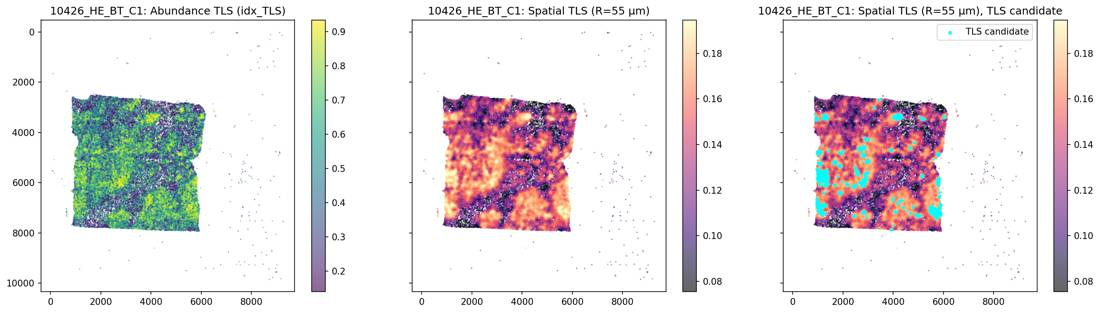

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/10426_HE_BT_C1_TLS_abundance_vs_spatial.png


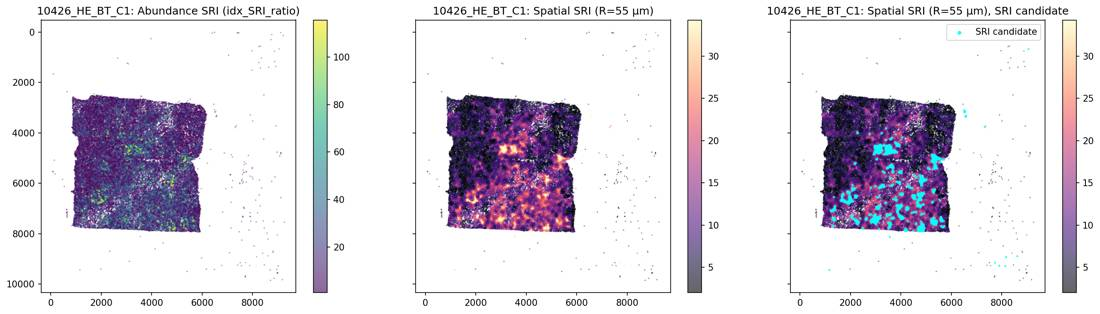

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/10426_HE_BT_C1_SRI_abundance_vs_spatial.png


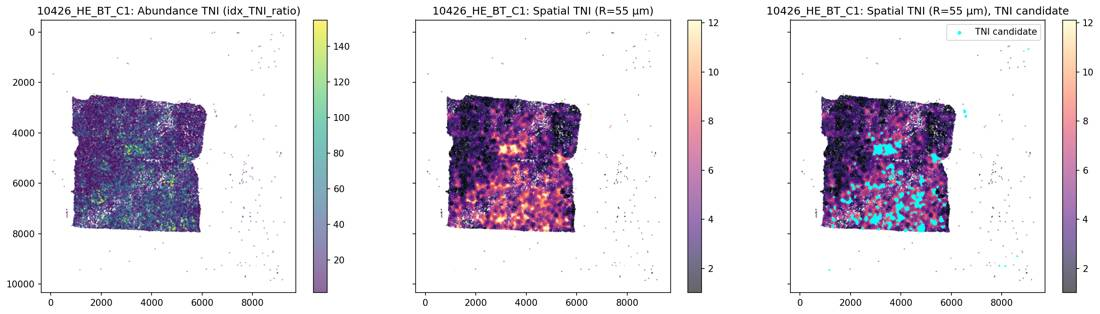

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/10426_HE_BT_C1_TNI_abundance_vs_spatial.png


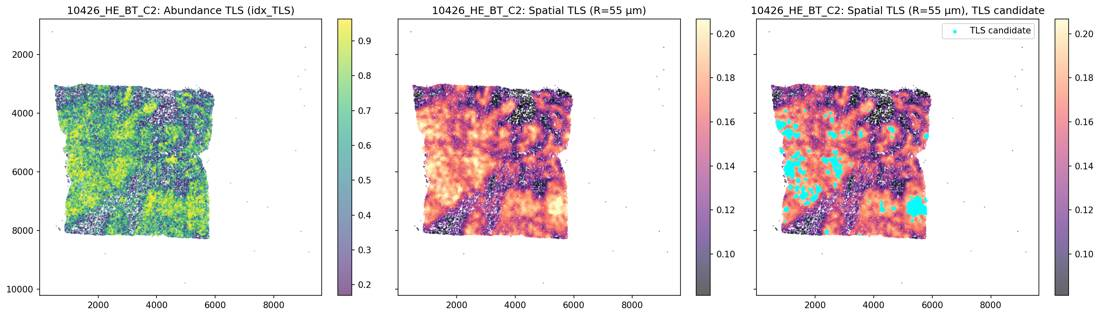

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/10426_HE_BT_C2_TLS_abundance_vs_spatial.png


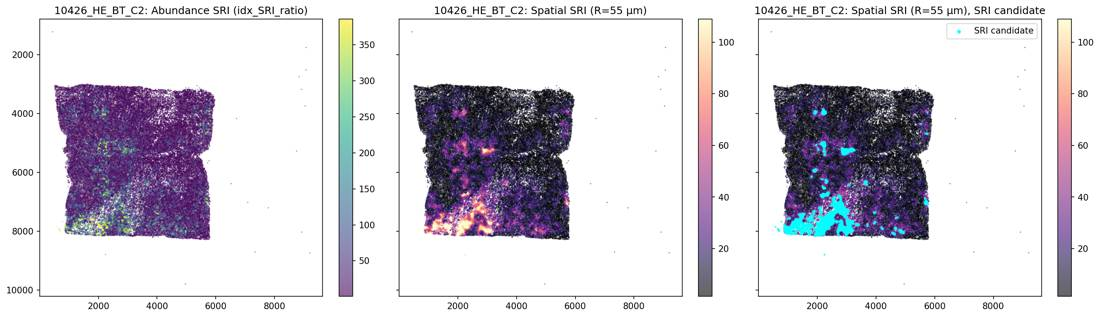

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/10426_HE_BT_C2_SRI_abundance_vs_spatial.png


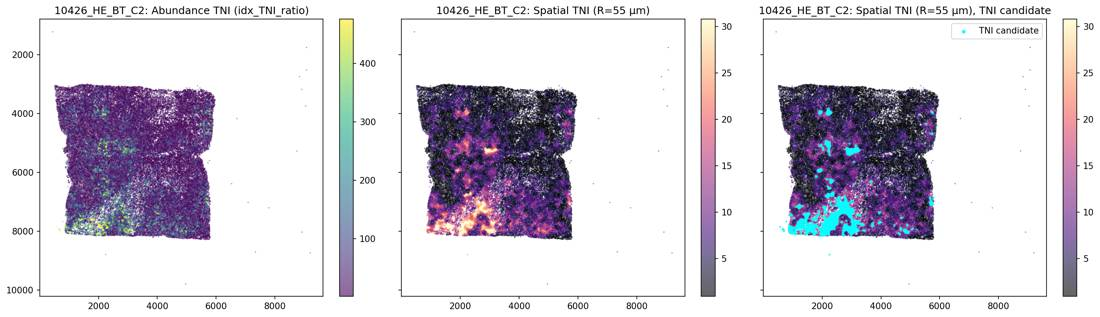

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/10426_HE_BT_C2_TNI_abundance_vs_spatial.png


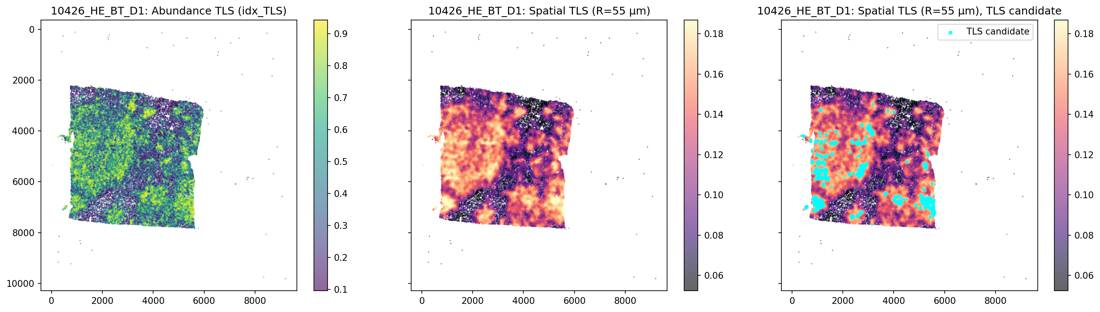

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/10426_HE_BT_D1_TLS_abundance_vs_spatial.png


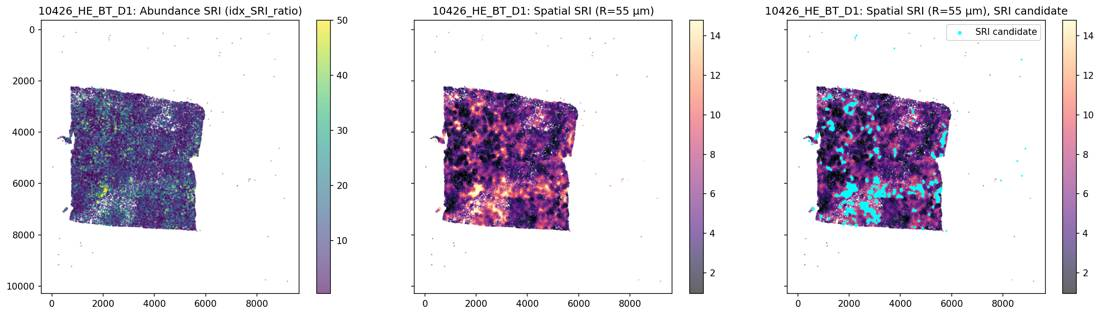

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/10426_HE_BT_D1_SRI_abundance_vs_spatial.png


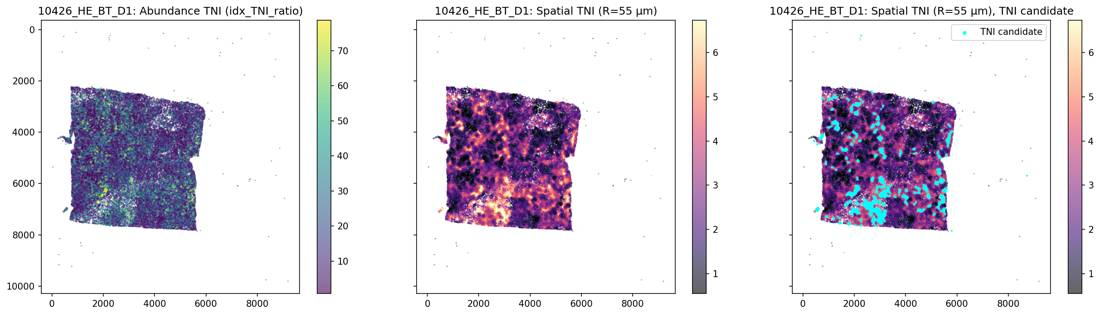

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/10426_HE_BT_D1_TNI_abundance_vs_spatial.png


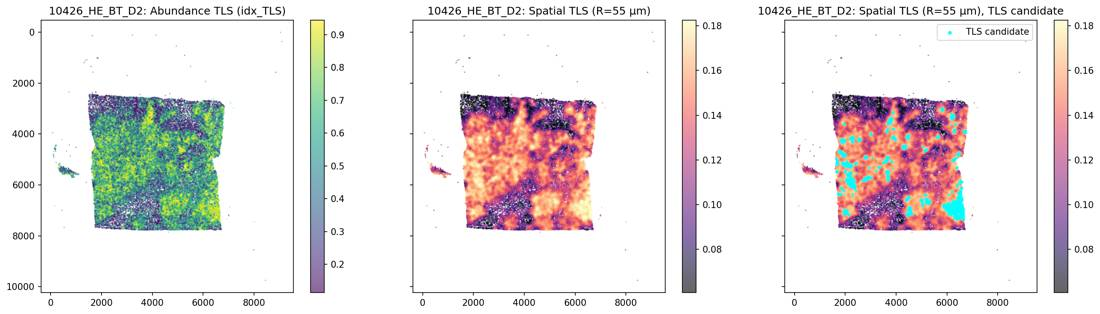

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/10426_HE_BT_D2_TLS_abundance_vs_spatial.png


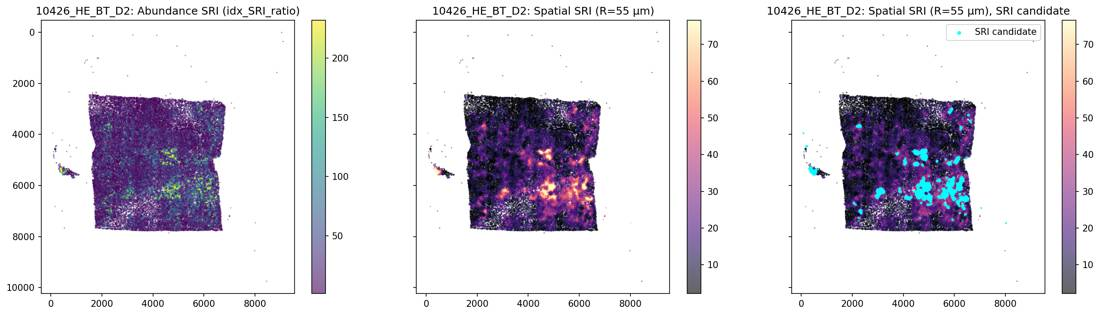

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/10426_HE_BT_D2_SRI_abundance_vs_spatial.png


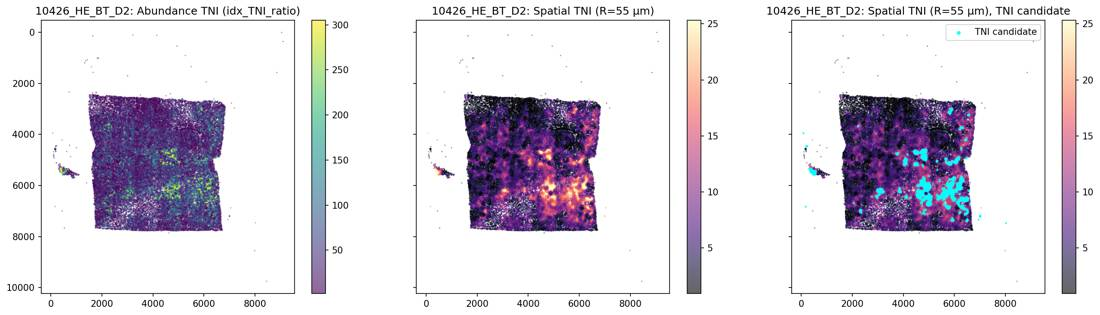

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/10426_HE_BT_D2_TNI_abundance_vs_spatial.png


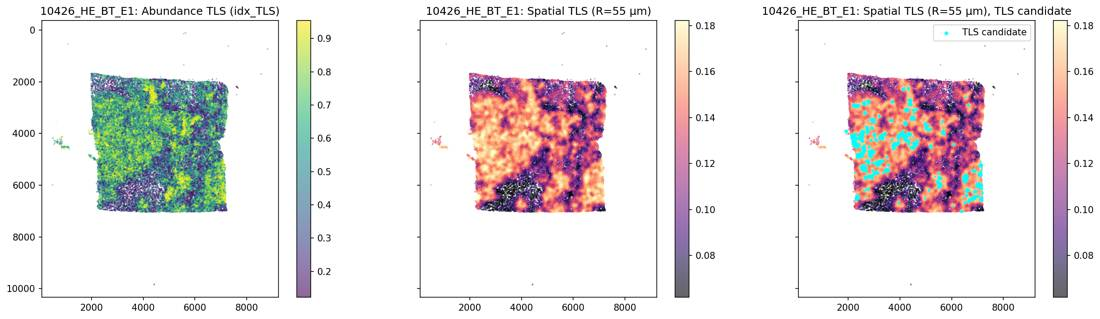

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/10426_HE_BT_E1_TLS_abundance_vs_spatial.png


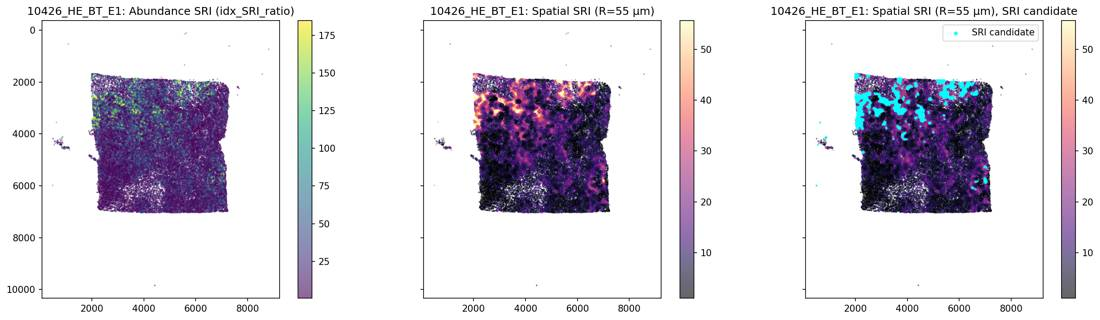

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/10426_HE_BT_E1_SRI_abundance_vs_spatial.png


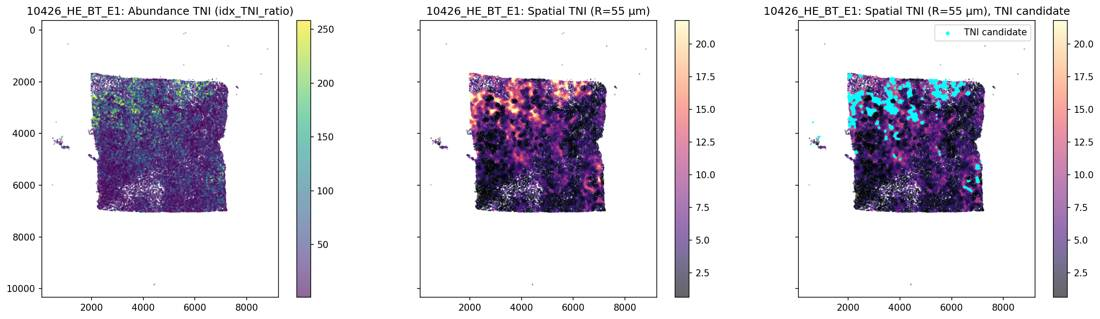

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/10426_HE_BT_E1_TNI_abundance_vs_spatial.png


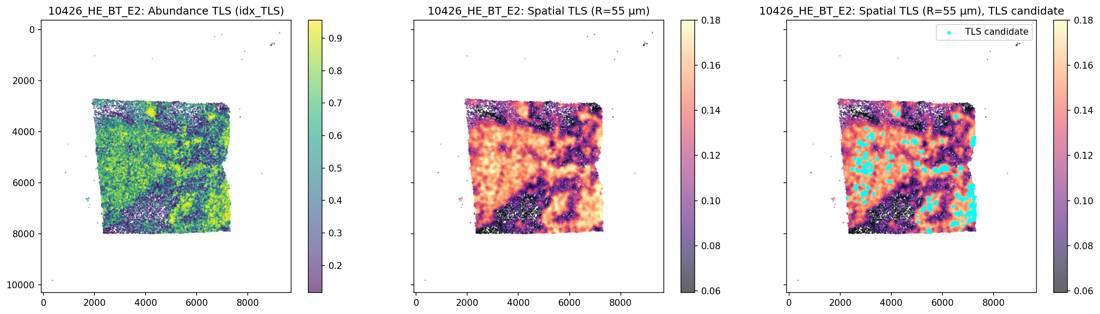

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/10426_HE_BT_E2_TLS_abundance_vs_spatial.png


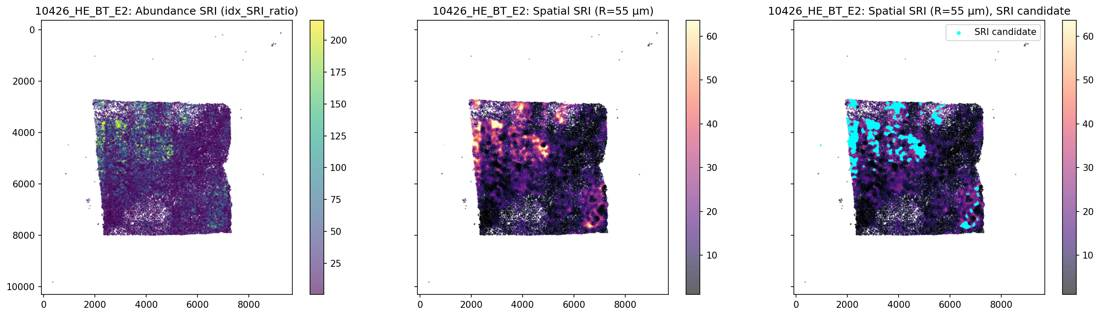

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/10426_HE_BT_E2_SRI_abundance_vs_spatial.png


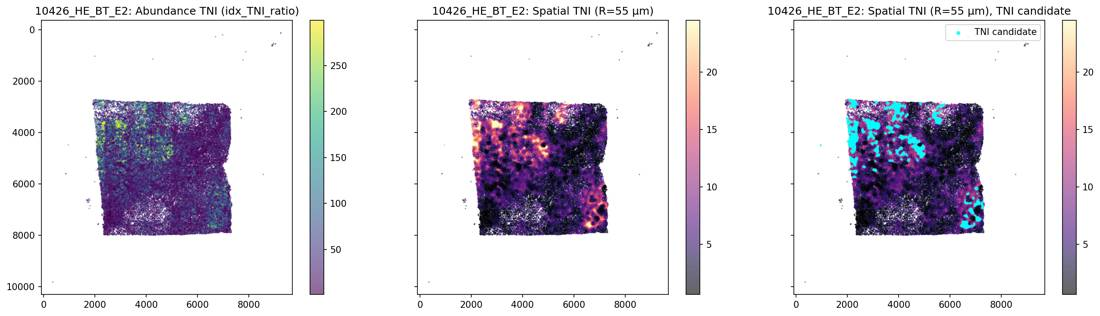

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/10426_HE_BT_E2_TNI_abundance_vs_spatial.png


In [4]:
import numpy as np

missing = [s for s in group if not sample_paths(s)["pred"].is_file()]
if missing:
    raise FileNotFoundError(
        f"No predictions yet for {PATIENT}: "
        + ", ".join(missing)
        + f". Run: SAMPLE={PATIENT} bash code/External_val/BRCA_ST/demo.sh all"
    )
display(Markdown(f"## {PATIENT} — TLS / SRI / TNI"))
frames = {}
for sample in group:
    paths = sample_paths(sample)
    niche_path = paths["pred"].with_name(f"{sample}_niche_indices.h5ad")
    mpp = float(geometry(sample)["mpp_um"])
    if niche_path.is_file() and not RECOMPUTE_NICHE:
        cached = ad.read_h5ad(niche_path)
        df = cached.obs.copy()
        xy = np.asarray(cached.obsm["spatial_HE"], dtype=np.float64)
        df["coord_x"] = xy[:, 0]
        df["coord_y"] = xy[:, 1]
        print(f"[niche] cache {niche_path.name}  n={len(df):,}  µm/px={mpp:.4f}")
    else:
        probs, class_names = ensure_l2_probs(sample)
        absent = hni.missing_index_cell_types(class_names, BRCA_ST_NICHE)
        if absent:
            raise RuntimeError(f"{sample} missing niche compartments: {absent}")
        pred = ad.read_h5ad(paths["pred"])
        coords = np.asarray(pred.obsm["spatial_HE"], dtype=np.float64)
        df = pred.obs.copy()
        df["coord_x"] = coords[:, 0]
        df["coord_y"] = coords[:, 1]
        df = hni.add_abundance_indices(df, probs, class_names, BRCA_ST_NICHE)
        df = hni.add_spatial_indices(
            df, probs, class_names, coords, BRCA_ST_NICHE,
            radius_um=TLS_RADIUS_UM,
            um_per_pixel=mpp,
        )
        out = ad.AnnData(obs=df.drop(columns=["coord_x", "coord_y"]))
        out.obsm["spatial_HE"] = coords
        out.uns["tls_radius_um"] = TLS_RADIUS_UM
        out.uns["um_per_px"] = mpp
        out.write_h5ad(niche_path)
        print(f"[niche] wrote {niche_path}  n={len(df):,}")
    frames[sample] = df
    print(f"  TLS hotspot: {hni.summarize_tls_hotspots(df)}")
    print(
        f"  mean TLS={df['idx_TLS'].mean():.3f}  TLS_spatial={df['idx_TLS_spatial'].mean():.3f}  "
        f"SRI={df['idx_SRI_ratio'].mean():.3f}  TNI={df['idx_TNI_ratio'].mean():.3f}"
    )

def tls_score_row(df, sample: str) -> dict:
    a = df["idx_TLS"].to_numpy(dtype=float)
    s = df["idx_TLS_spatial"].to_numpy(dtype=float)
    a_hi = a >= np.percentile(a, 95)
    s_hi = df["tls_candidate"].fillna(False).astype(bool).to_numpy()
    inter = int(np.logical_and(a_hi, s_hi).sum())
    union = int(np.logical_or(a_hi, s_hi).sum())
    n_a = int(a_hi.sum())
    return {
        "sample": sample,
        "n": int(len(df)),
        "TLS_mean": float(np.mean(a)),
        "TLS_median": float(np.median(a)),
        "TLS_p95": float(np.percentile(a, 95)),
        "TLS_max": float(np.max(a)),
        "TLS_spatial_mean": float(np.mean(s)),
        "TLS_spatial_median": float(np.median(s)),
        "TLS_spatial_p95": float(np.percentile(s, 95)),
        "TLS_spatial_max": float(np.max(s)),
        "pearson": float(np.corrcoef(a, s)[0, 1]),
        "spearman": float(pd.Series(a).corr(pd.Series(s), method="spearman")),
        "top5_jaccard": (inter / union) if union else float("nan"),
        "abundance_top5_also_spatial_top5": (inter / n_a) if n_a else float("nan"),
        "TLS_spatial_mean_in_abundance_top5": float(s[a_hi].mean()) if n_a else float("nan"),
        "TLS_mean_in_spatial_top5": float(a[s_hi].mean()) if s_hi.any() else float("nan"),
    }

tls_quant = pd.DataFrame([tls_score_row(df, sample) for sample, df in frames.items()])
tls_quant_path = fig_dir / f"tls_score_summary_{PATIENT}.csv"
tls_quant.to_csv(tls_quant_path, index=False)
print(tls_quant_path)
display(tls_quant.round(3))

for sample, df in frames.items():
    fig, axes = hdni.plot_tls_abundance_vs_spatial(
        df,
        sample,
        radius_um=TLS_RADIUS_UM,
        use_entropy=False,
        split_spatial_candidates=True,
        point_size=0.15,
        candidate_size=1.2,
        save_path=(fig_dir / f"{sample}_TLS_abundance_vs_spatial.png") if SAVE_FIGURES else None,
    )
    display(fig)
    plt.close(fig)
    for abundance_col, spatial_col, candidate_col, tag in (
        ("idx_SRI_ratio", "idx_SRI_spatial", "sri_candidate", "SRI"),
        ("idx_TNI_ratio", "idx_TNI_spatial", "tni_candidate", "TNI"),
    ):
        fig, axes = hdni.plot_tls_abundance_vs_spatial(
            df,
            sample,
            radius_um=TLS_RADIUS_UM,
            abundance_col=abundance_col,
            spatial_col=spatial_col,
            candidate_col=candidate_col,
            score_name=tag,
            use_entropy=False,
            split_spatial_candidates=True,
            point_size=0.15,
            candidate_size=1.2,
            save_path=(fig_dir / f"{sample}_{tag}_abundance_vs_spatial.png") if SAVE_FIGURES else None,
        )
        display(fig)
        plt.close(fig)
